In [3]:
import seaborn as sns

# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [2]:
# Checking missing values in each column
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [5]:
# Fill missing payment values using mode
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

# Remove rows with missing critical location information
df = df.dropna(subset=[
    'pickup_zone',
    'dropoff_zone',
    'pickup_borough',
    'dropoff_borough'
])




### payment: Fill missing values using mode because it is a categorical column.
 
### Location columns: Remove rows with missing values because the actual pickup and dropoff locations cannot be reliably determined.

### Numerical columns: No action required because they have no missing values.

In [6]:
# Check missing values after handling
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

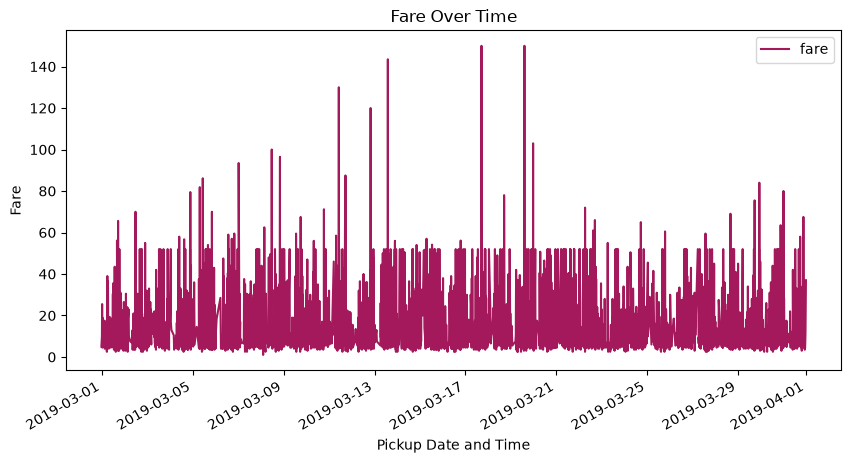

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert pickup column to datetime format
df['pickup'] = pd.to_datetime(df['pickup'])

# Plot line chart
df.sort_values('pickup').plot(
    x='pickup',
    y='fare',
    kind='line',
    figsize=(10, 5),
    color='#A3195B'
)

plt.title('Fare Over Time')
plt.xlabel('Pickup Date and Time')
plt.ylabel('Fare')
plt.show()

### Findings and Insights – Line Chart

#### **Findings:**

##### - Taxi fares fluctuate frequently throughout March 2019.
##### - Most fares are approximately between $5 and $50.
##### - A few high-fare trips reach approximately $150.

#### **Insights:**

##### - Most trips have relatively low to moderate fares.
##### - Occasional high-fare trips create noticeable spikes.
##### - No clear increasing or decreasing trend is observed during the month.

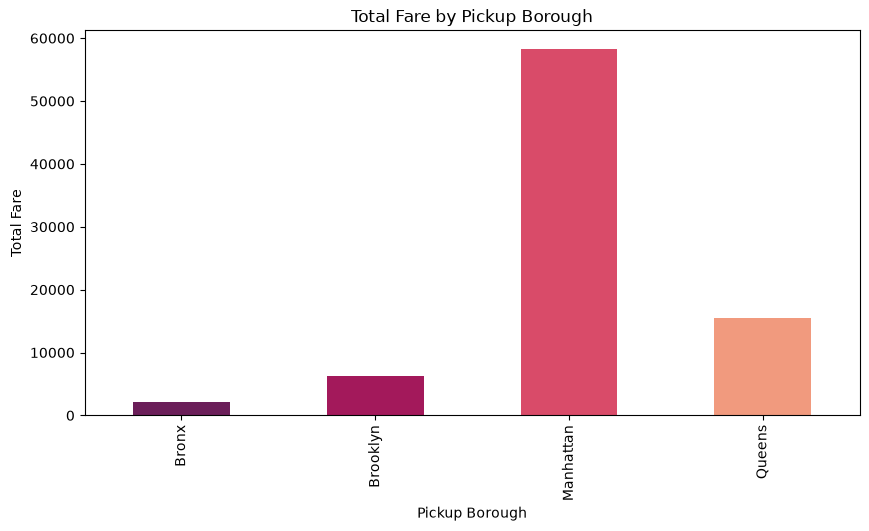

In [41]:
# Group by pickup_borough and calculate total fare
total_fare = df.groupby('pickup_borough')['fare'].sum()

# Plot bar chart
total_fare.plot(kind='bar', figsize=(10, 5),
                color=['#6B1E59', '#A3195B', '#D94B69', '#F19A7E'])

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.show()

### Findings and Insights – Bar Chart

**Findings:**
- Manhattan records the highest total fare, approximately USD 58,000, followed by Queens at USD 15,500.
- Brooklyn generates approximately USD 6,000, while the Bronx has the lowest total fare at around USD 2,000.
- Total fare amounts vary significantly across the four pickup boroughs.

**Insights:**
- Manhattan is the largest contributor to total taxi fare revenue.
- Queens is the second-largest contributor, while Brooklyn and the Bronx contribute comparatively less.
- Differences in total fares may be influenced by trip frequency, distance, and fare amounts across boroughs.

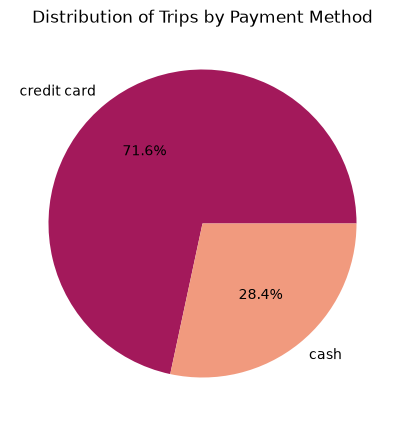

In [20]:
# Count trips for each payment method
payment_counts = df['payment'].value_counts()

# Plot pie chart
payment_counts.plot(
    kind='pie',
    figsize=(10, 5),
    autopct='%1.1f%%',
    colors=['#A3195B', '#F19A7E']
)

plt.title('Distribution of Trips by Payment Method')
plt.ylabel('')
plt.show()

### Findings and Insights – Pie Chart

**Findings:**
- Credit card payments account for 71.9% of total taxi trips.
- Cash payments represent the remaining 28.1% of trips.
- Credit card payments are more than twice as common as cash payments.

**Insights:**
- Credit cards are the dominant payment method among taxi passengers in the dataset.
- The higher proportion of credit card transactions indicates a greater use of cashless payments.
- Cash remains a significant payment option, accounting for more than one-quarter of trips.

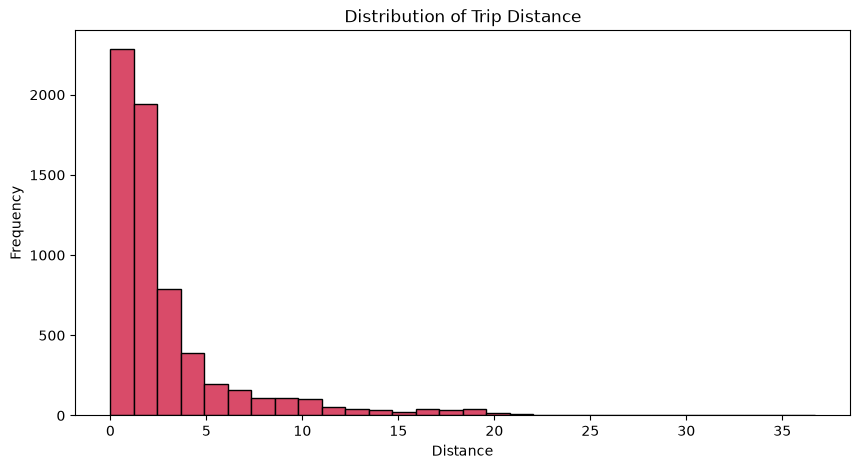

In [43]:
# Plot histogram for distance
df['distance'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 5),
    color='#D94B69',
    edgecolor='black'
)

plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.show()

### Findings and Insights – Histogram

**Findings:**
- Most taxi trips cover short distances, primarily between 0 and 5 miles.
- The frequency of trips decreases as the distance increases.
- A few trips cover longer distances, extending beyond 20 miles.
- The distribution is right-skewed, with a long tail toward higher distances.

**Insights:**
- Short-distance trips are more common than long-distance trips in the dataset.
- The right-skewed distribution indicates that most trips have relatively low distances, while a small number are considerably longer.
- Longer-distance trips are relatively rare compared to shorter trips.

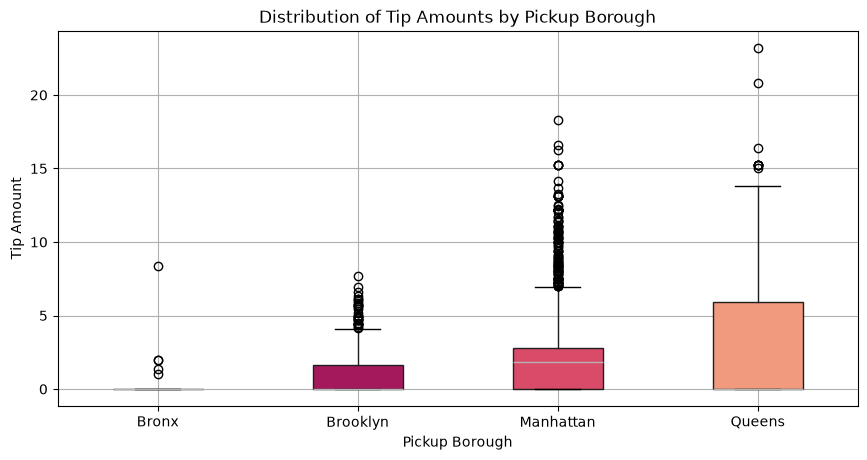

In [46]:
# Plot box plot for tip amounts by pickup borough
box_plot=df.boxplot(
    column='tip',
    by='pickup_borough',
    figsize=(10, 5),
    patch_artist=True
)
# Add different colors to each box
colors = ['#6B1E59', '#A3195B', '#D94B69', '#F19A7E']

for box, color in zip(box_plot.patches, colors):
    box.set_facecolor(color)


plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.show()

### Findings and Insights – Box Plot

**Findings:**
- The Bronx has the lowest tip amounts, with most values concentrated around zero.
- Brooklyn shows relatively low tip amounts, with several outliers reaching approximately 7.5.
- Manhattan has a median tip of approximately 1.5, with numerous high-value outliers.
- Queens shows the greatest variation in tip amounts, with outliers exceeding 20.

**Insights:**
- Tipping patterns vary across pickup boroughs.
- Manhattan has a higher typical tip amount than the Bronx and Brooklyn.
- Queens exhibits greater variability in tipping, indicating a wider range of tip amounts.
- The presence of outliers suggests that some passengers provide significantly higher tips than most others.

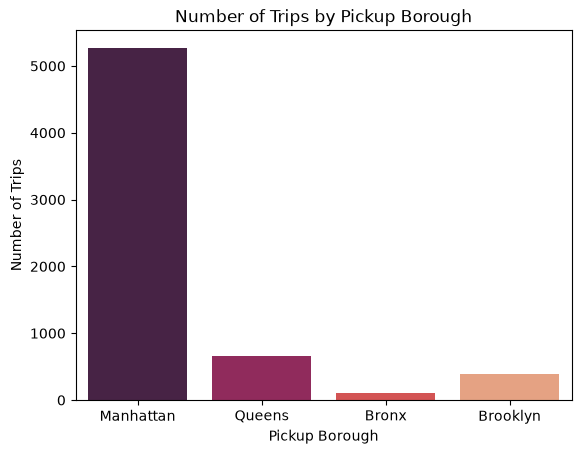

In [17]:
# Plot count plot for trips by pickup borough
sns.countplot(
    data=df,
    x='pickup_borough',
    hue='pickup_borough',
    palette='rocket',
    legend=False
)

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.show()

### Findings and Insights – Count Plot

**Findings:**
- Manhattan records the highest number of taxi trips, approximately 5,250.
- Queens ranks second with around 650 trips, followed by Brooklyn with approximately 370 trips.
- The Bronx has the lowest number of trips, with approximately 100 recorded.
- Trip counts vary significantly across the four pickup boroughs.

**Insights:**
- Manhattan dominates taxi pickup activity, accounting for the majority of recorded trips.
- Queens and Brooklyn contribute considerably fewer trips compared to Manhattan.
- The Bronx shows the lowest taxi pickup activity in the dataset.
- The differences in trip counts indicate an uneven distribution of taxi pickups across boroughs.

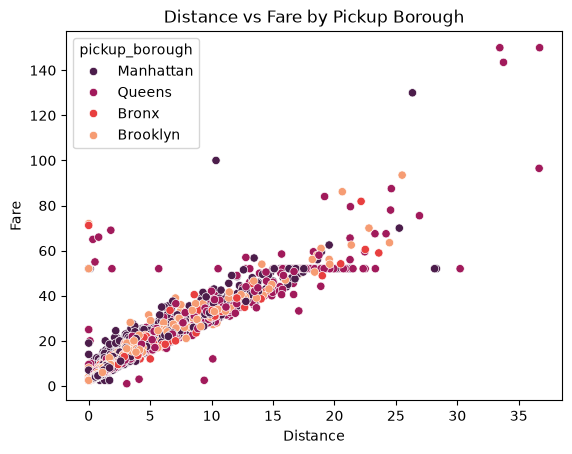

In [18]:
# Plot scatter plot for distance vs fare
sns.scatterplot(
    data=df,
    x='distance',
    y='fare',
    hue='pickup_borough',
    palette='rocket'
)

plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.show()

### Findings and Insights – Scatter Plot

**Findings:**
- The scatter plot shows a positive relationship between trip distance and fare.
- Most taxi trips are concentrated within distances of 0 to 15 miles, with fares generally below 50.
- A few longer trips have significantly higher fares, reaching approximately 150.
- Trips from different pickup boroughs follow a broadly similar increasing pattern.

**Insights:**
- Longer taxi trips generally result in higher fares, indicating a positive correlation between distance and fare.
- Most trips involve relatively short distances and lower fare amounts.
- A few high-fare trips stand out from the general pattern.
- The overlapping points across boroughs suggest that the distance-fare relationship is broadly similar across pickup locations.

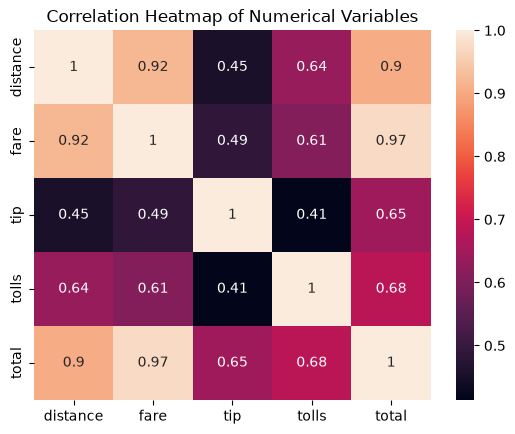

In [13]:
# Calculate correlation matrix
correlation_matrix = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()

# Plot heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='rocket'
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

### Findings and Insights – Heatmap

**Findings:**
- Fare and total have the strongest positive correlation (0.97).
- Distance shows a strong positive correlation with fare (0.95) and total (0.93).
- Tolls have a moderate positive correlation with total (0.69) and distance (0.64).
- Tip has a moderate positive correlation with total (0.65), while its correlation with distance (0.48) and fare (0.49) is comparatively weaker.
- All five numerical variables show positive correlations with one another.

**Insights:**
- Longer taxi trips are strongly associated with higher fare amounts and total charges.
- Fare is closely related to the total trip cost.
- Tips and tolls contribute to total charges but show weaker relationships with other variables compared to fare and distance.
- The correlation matrix highlights distance and fare as important variables associated with total taxi trip charges.

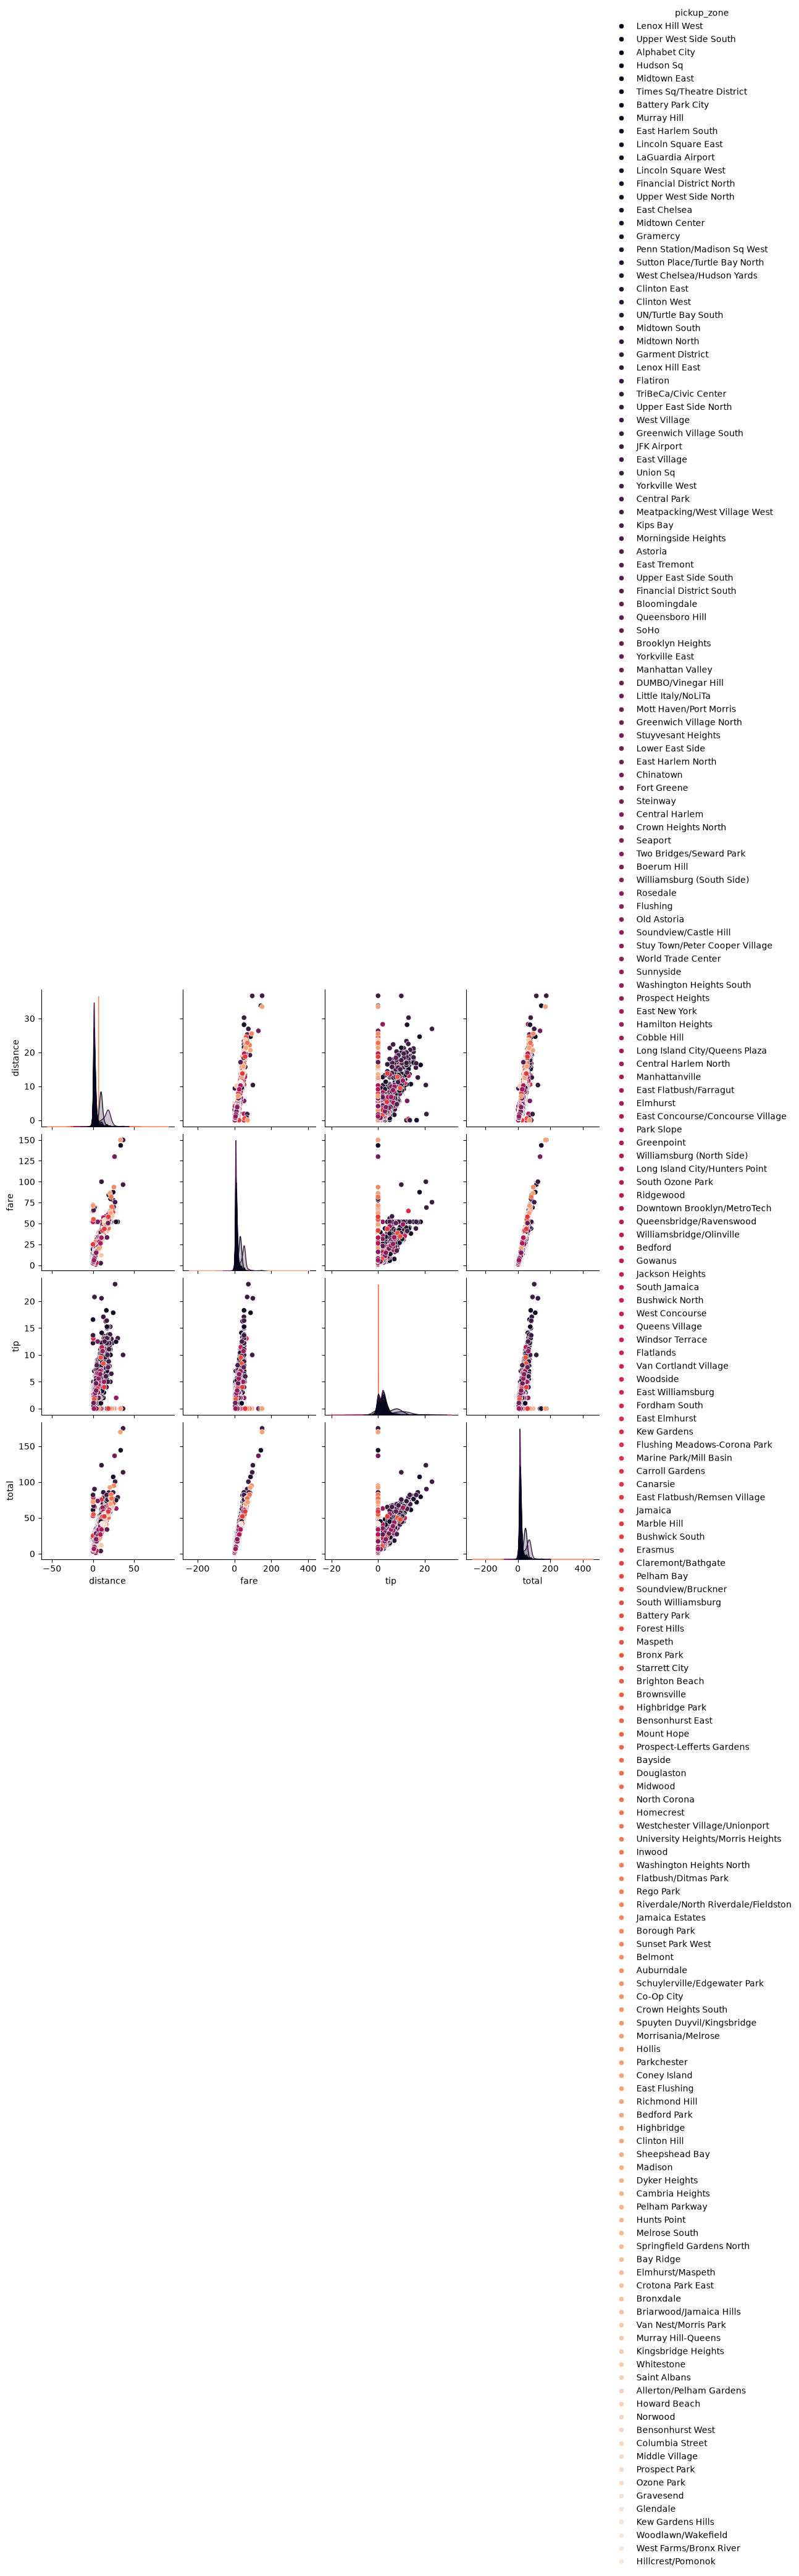

In [15]:
# Plot pairwise relationships between numerical variables
g = sns.pairplot(
    data=df,
    vars=['distance', 'fare', 'tip', 'total'],
    hue='pickup_zone',
    palette='rocket'
)

plt.show()

### Findings and Insights – Pair Plot

**Findings:**

1. The pair plot shows a strong positive relationship between trip distance and fare.
2. Total fare also increases as trip distance and fare increase.
3. Tip amounts show a weaker relationship with distance and fare, indicating greater variation in tipping behavior.
4. Most trips are concentrated at lower distances, fares, tips, and total amounts.
5. Different pickup zones are represented by different colors, although the large number of zones makes individual comparisons difficult.

**Insights:**

1. Trip distance is an important factor influencing fare and total trip cost.
2. Fare and total are closely related because fare contributes directly to the total amount.
3. Tipping behavior varies across trips and is not determined by trip distance alone.
4. The pair plot helps identify overall relationships and unusual values, but the large number of pickup zones limits clear zone-by-zone comparisons.

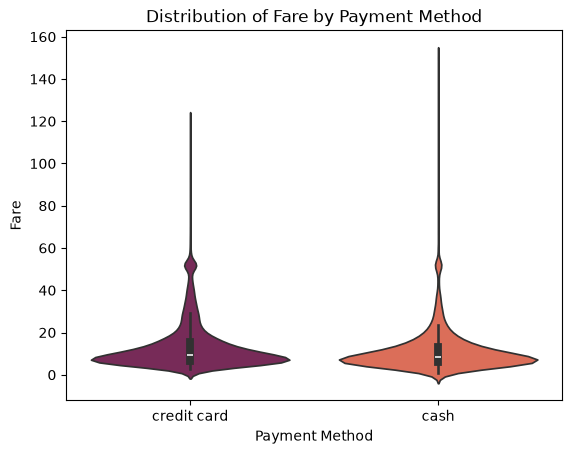

In [16]:
# Create violin plot for fare by payment method
sns.violinplot(
    data=df,
    x='payment',
    y='fare',
    hue='payment',
    palette='rocket',
    legend=False
)

plt.title('Distribution of Fare by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.show()

### Findings and Insights – Violin Plot

**Findings:**

1. The violin plot shows the distribution of fare amounts for credit card and cash payments.
2. Most fare amounts for both payment methods are concentrated in the lower fare range, particularly below 20.
3. Both payment methods show similar central fare distributions, with most trips having relatively low fares.
4. Cash payments show a slightly wider spread in some fare ranges compared to credit card payments.
5. Both payment methods have long upper tails, indicating a small number of trips with unusually high fares.

**Insights:**

1. Lower-fare trips are common for both credit card and cash payments.
2. The overall fare distributions are broadly similar across the two payment methods.
3. High-fare trips occur with both payment methods but are relatively uncommon.
4. Payment method alone does not appear to strongly differentiate fare amounts in this dataset.